Proyek Klasifikasi Gambar: mikoajkolman/pokemon-images-first-generation17000-files

Nama: ASEP HARYANA SAPUTRA

Email: superaseph@gmail.com

ID Dicoding: mytheclipse

## 1. Persiapan Lingkungan

Mengimpor semua pustaka yang diperlukan dan mengatur seed untuk reproduksibilitas.

In [1]:
!pip install -r requirements.txt

In [2]:
# Import semua pustaka di awal
import os
import shutil
import zipfile
import random
import io
import logging
import traceback
import time
import psutil
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
import splitfolders  # untuk split dataset

# Keras / TF
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras import layers, models, callbacks, regularizers
from tensorflow.keras.applications import MobileNetV3Large
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input
from tensorflow.keras.optimizers import AdamW

# Sklearn
from sklearn.metrics import confusion_matrix, classification_report

# Widget interaktif
import ipywidgets as widgets
from IPython.display import display, clear_output

# Konfigurasi global
IMG_SIZE = (256, 256)
BATCH_SIZE = 32
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Optimasi performa TF
os.environ["TF_DATA_AUTOTUNE_RAM_BUDGET"] = "4000000000"
os.environ['TF_XLA_FLAGS'] = '--tf_xla_enable_xla_devices=false'

# Gunakan mixed precision untuk mempercepat training (jika GPU mendukung)
tf.keras.mixed_precision.set_global_policy('mixed_float16')

print(f"Setup selesai. IMG_SIZE={IMG_SIZE}, BATCH_SIZE={BATCH_SIZE}")

2026-02-16 18:56:52.831610: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-02-16 18:56:52.839705: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1771243012.849028  333348 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1771243012.852193  333348 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1771243012.859482  333348 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

Setup selesai. IMG_SIZE=(256, 256), BATCH_SIZE=32


## 2. Ekstraksi Dataset

Dataset disediakan dalam file `pokemon.zip`. Ekstrak ke folder `dataset_raw`.

In [3]:
zip_filename = 'pokemon.zip'
extract_dir = 'dataset_raw'

# Ekstrak hanya jika folder belum ada atau kosong
if os.path.exists(extract_dir) and len(os.listdir(extract_dir)) > 0:
    print(f"Folder {extract_dir} sudah ada dan tidak kosong. Ekstraksi dilewati.")
else:
    if os.path.exists(extract_dir):
        shutil.rmtree(extract_dir)
    os.makedirs(extract_dir, exist_ok=True)
    with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    print("Ekstraksi selesai.")

Folder dataset_raw sudah ada dan tidak kosong. Ekstraksi dilewati.


## 3. Pembersihan Data

Langkah-langkah:
- Gabungkan kelas duplikat (misal 'Mr. Mime' dan 'MrMime').
- Hapus file non-gambar (selain .jpg, .jpeg, .png, .bmp).
- Hapus file gambar corrupt.
- Normalisasi metadata gambar (konversi ke RGB, hapus profil ICC).

In [4]:
# Tentukan direktori utama dataset
base_dir = os.path.join(extract_dir, 'pokemon')
if not os.path.exists(base_dir):
    base_dir = extract_dir  # jika tidak ada subfolder pokemon
print(f"Direktori utama: {base_dir}")

# 1. Gabungkan kelas duplikat
duplicate_map = {'Mr. Mime': 'MrMime'}
for src, dst in duplicate_map.items():
    src_path = os.path.join(base_dir, src)
    dst_path = os.path.join(base_dir, dst)
    if os.path.exists(src_path):
        if os.path.exists(dst_path):
            # Pindahkan semua file dari src ke dst
            for f in os.listdir(src_path):
                shutil.move(os.path.join(src_path, f), os.path.join(dst_path, f))
            shutil.rmtree(src_path)
            print(f"Digabungkan {src} ke {dst}")
        else:
            os.rename(src_path, dst_path)
            print(f"Diganti nama {src} -> {dst}")

# 2. Hapus file non-gambar dan corrupt
valid_ext = ('.jpg', '.jpeg', '.png', '.bmp')
removed = 0
for root, dirs, files in os.walk(base_dir):
    for file in files:
        fpath = os.path.join(root, file)
        ext = os.path.splitext(file)[1].lower()
        if ext not in valid_ext:
            os.remove(fpath)
            removed += 1
            continue
        try:
            with Image.open(fpath) as img:
                img.verify()  # cek integritas
        except Exception:
            os.remove(fpath)
            removed += 1
print(f"File dihapus (ekstensi tidak valid/corrupt): {removed}")

# 3. Bersihkan folder kelas yang kosong
for d in os.listdir(base_dir):
    dpath = os.path.join(base_dir, d)
    if os.path.isdir(dpath) and len(os.listdir(dpath)) == 0:
        shutil.rmtree(dpath)
        print(f"Folder kosong dihapus: {d}")

# 4. Normalisasi metadata (konversi ke RGB, hapus ICC profile)
sanitized = 0
for root, dirs, files in os.walk(base_dir):
    for file in files:
        fpath = os.path.join(root, file)
        try:
            with Image.open(fpath) as img:
                if img.mode != 'RGB' or 'icc_profile' in img.info:
                    img = img.convert('RGB')
                    img.save(fpath, 'JPEG', quality=95, optimize=True)
                    sanitized += 1
        except Exception:
            pass
print(f"Gambar dinormalisasi: {sanitized}")

# Hitung total gambar dan kelas
class_counts = {}
total_images = 0
for d in os.listdir(base_dir):
    dpath = os.path.join(base_dir, d)
    if os.path.isdir(dpath):
        cnt = len(os.listdir(dpath))
        class_counts[d] = cnt
        total_images += cnt
print(f"Total gambar valid: {total_images} dari {len(class_counts)} kelas")

Direktori utama: dataset_raw/pokemon
File dihapus (ekstensi tidak valid/corrupt): 0
Gambar dinormalisasi: 0
Total gambar valid: 16485 dari 142 kelas


## 4. Pembagian Dataset (Train:Validation:Test = 60:20:20)

Menggunakan library `split-folders` untuk membagi secara proporsional.

In [5]:
output_dir = 'dataset_split'
if os.path.exists(output_dir):
    shutil.rmtree(output_dir)

splitfolders.ratio(
    base_dir,
    output=output_dir,
    seed=SEED,
    ratio=(0.6, 0.2, 0.2),
    group_prefix=None
)

train_dir = os.path.join(output_dir, 'train')
val_dir = os.path.join(output_dir, 'val')
test_dir = os.path.join(output_dir, 'test')

def count_images(path):
    return sum(len(files) for _, _, files in os.walk(path))

print(f"Train set: {count_images(train_dir)} gambar")
print(f"Validation set: {count_images(val_dir)} gambar")
print(f"Test set: {count_images(test_dir)} gambar")

Copying files: 16485 files [00:03, 4662.58 files/s]

Train set: 9835 gambar
Validation set: 3239 gambar
Test set: 3411 gambar


## 5. Persiapan Data Loader dengan Augmentasi

Menggunakan `image_dataset_from_directory` untuk membaca gambar.  
Augmentasi diterapkan pada data training dengan intensitas sedang dan ditambah GaussianNoise.

In [6]:
# Load dataset
train_ds = image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=None,
    label_mode='categorical',
    shuffle=True,
    seed=SEED
)
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

# Batching
train_ds = train_ds.batch(BATCH_SIZE, drop_remainder=True)
val_ds = image_dataset_from_directory(
    val_dir, image_size=IMG_SIZE, batch_size=None, label_mode='categorical', shuffle=False, seed=SEED
).batch(BATCH_SIZE, drop_remainder=True)
test_ds = image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=None, label_mode='categorical', shuffle=False, seed=SEED
).batch(BATCH_SIZE, drop_remainder=True)

print(f"Jumlah kelas: {NUM_CLASSES}")
print(f"Contoh kelas: {class_names[:5]}...")

# Augmentasi yang lebih bervariasi dengan penambahan GaussianNoise untuk regularisasi
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.15),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomBrightness(0.15),
    layers.GaussianNoise(0.01),  # Menambah noise kecil untuk regularisasi
])

# Fungsi preprocessing
def preprocess(images, labels):
    return preprocess_input(images), labels

def augment_and_preprocess(images, labels):
    x = data_augmentation(images)
    return preprocess_input(x), labels

# Terapkan
AUTOTUNE = tf.data.AUTOTUNE
train_generator = train_ds.map(augment_and_preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
validation_generator = val_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_generator = test_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

Found 9835 files belonging to 142 classes.


I0000 00:00:1771243019.823467  333348 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2931 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Found 3239 files belonging to 142 classes.
Found 3411 files belonging to 142 classes.
Jumlah kelas: 142
Contoh kelas: ['Abra', 'Aerodactyl', 'Alakazam', 'Arbok', 'Arcanine']...


## 6. Visualisasi Sampel Data (dengan Augmentasi)

Menampilkan beberapa gambar dari training set yang telah diaugmentasi.

2026-02-16 18:57:00.771059: E tensorflow/core/util/util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


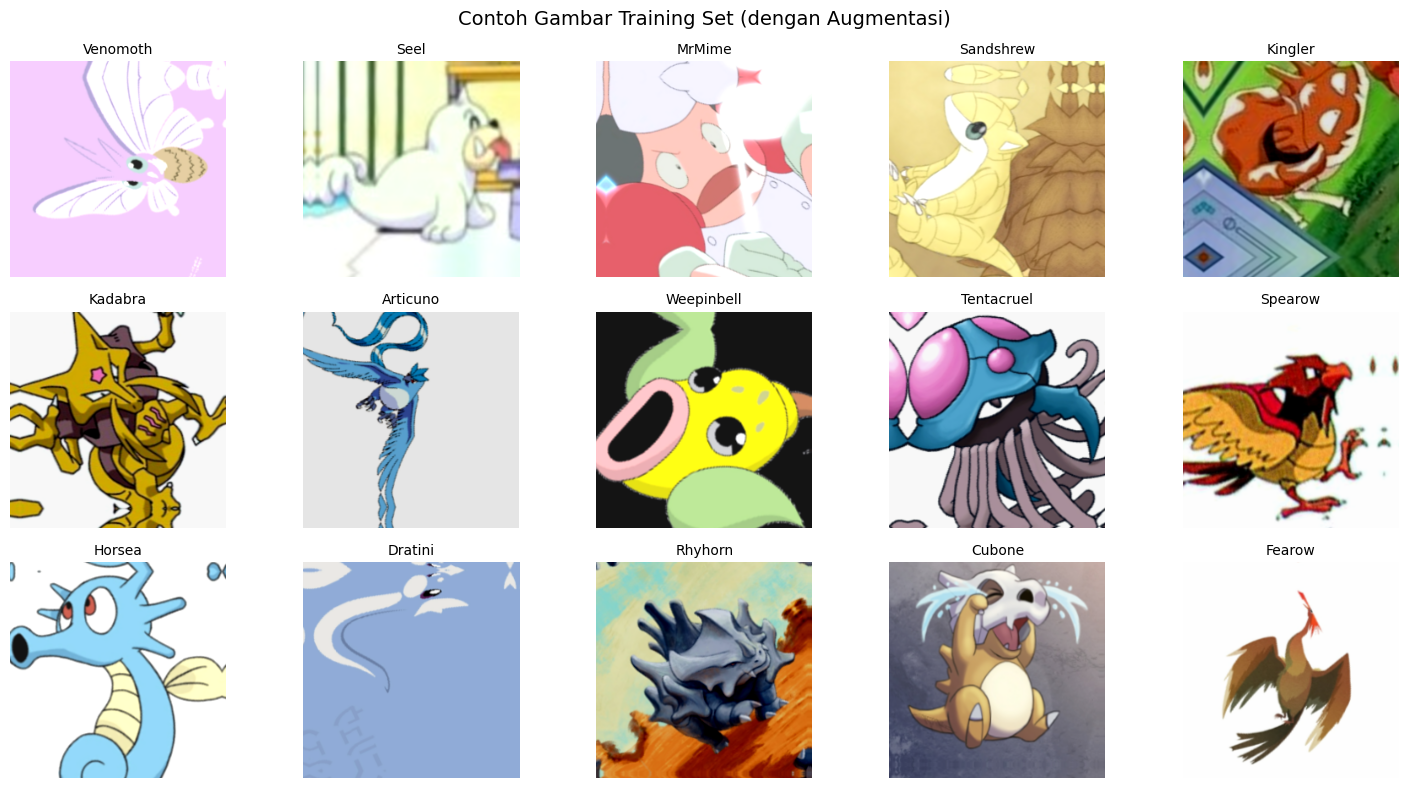

In [7]:
sample_images, sample_labels = next(iter(train_generator))

plt.figure(figsize=(15, 8))
for i in range(15):
    plt.subplot(3, 5, i+1)
    img_np = sample_images[i].numpy().astype("uint8")
    plt.imshow(img_np)
    label_idx = np.argmax(sample_labels[i])
    plt.title(class_names[label_idx], fontsize=10)
    plt.axis('off')
plt.suptitle('Contoh Gambar Training Set (dengan Augmentasi)', fontsize=14)
plt.tight_layout()
plt.show()

## 7. Penanganan Ketidakseimbangan Kelas dengan Sample Weight

Hitung bobot untuk setiap kelas berdasarkan frekuensi di training set, lalu tambahkan ke pipeline data. Bobot dibatasi maksimum 3.0 untuk menghindari bobot ekstrem.

In [8]:
# Hitung jumlah sampel per kelas di training
train_class_counts = Counter()
for class_name in class_names:
    folder = os.path.join(train_dir, class_name)
    if os.path.exists(folder):
        train_class_counts[class_name] = len(os.listdir(folder))

total_samples = sum(train_class_counts.values())
class_weights_list = []
for class_name in class_names:
    count = train_class_counts.get(class_name, 1)
    weight = total_samples / (NUM_CLASSES * count)
    # Batasi bobot maksimum agar tidak terlalu ekstrem
    weight = min(weight, 3.0)   # Diturunkan dari 5.0 menjadi 3.0
    class_weights_list.append(weight)

class_weights_tensor = tf.constant(class_weights_list, dtype=tf.float32)

# Fungsi untuk menambahkan sample weight ke dataset
def add_sample_weight(image, label):
    class_indices = tf.argmax(label, axis=-1)
    sample_weights = tf.gather(class_weights_tensor, class_indices)
    return image, label, sample_weights

# Terapkan sample weight pada training generator
train_generator = train_generator.map(add_sample_weight, num_parallel_calls=AUTOTUNE)

# Tampilkan statistik bobot
print("Bobot kelas (dibatasi max 3.0):")
for i, name in enumerate(class_names[:10]):
    print(f"{name}: {class_weights_list[i]:.4f}")
print("...")

Bobot kelas (dibatasi max 3.0):
Abra: 1.9239
Aerodactyl: 1.3581
Alakazam: 1.3581
Arbok: 0.8995
Arcanine: 1.4429
Articuno: 1.2593
Beedrill: 1.3319
Bellsprout: 0.8880
Blastoise: 0.8148
Bulbasaur: 0.7871
...


## 8. Membangun Model CNN dengan Transfer Learning

Menggunakan MobileNetV3Large sebagai basis dengan dropout internal diaktifkan (0.3). Ditambah layer klasifikasi dengan regularisasi L2 dan dropout lebih tinggi (0.6) untuk mengurangi overfitting.

In [9]:
def create_model():
    # Base model dengan dropout_rate diaktifkan
    base_model = MobileNetV3Large(
        input_shape=IMG_SIZE + (3,),
        include_top=False,
        weights='imagenet',
        dropout_rate=0.3  # Mengaktifkan dropout internal MobileNet
    )
    base_model.trainable = False  # bekukan dulu

    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(1024, kernel_regularizer=regularizers.l2(1e-4)),  # L2 regularizer
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.6),  # Ditingkatkan menjadi 0.6
        layers.Dense(NUM_CLASSES, activation='softmax', dtype='float32')
    ])
    return model

checkpoint_path = 'submission/best_model.keras'
if os.path.exists(checkpoint_path):
    print(f"Memuat model terbaik dari {checkpoint_path}...")
    model = models.load_model(checkpoint_path)
else:
    print("Membuat model baru dengan regularisasi ditingkatkan...")
    model = create_model()

model.summary()

Memuat model terbaik dari submission/best_model.keras...


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MobileNetV3Large (Functional)   │ (None, 8, 8, 960)      │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 960)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │       984,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_20 (Activation)      │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 142)            │       145,550 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,337,296 (47.06 MB)

 Trainable params: 4,103,614 (15.65 MB)

 Non-trainable params: 26,448 (103.31 KB)

 Optimizer params: 8,207,234 (31.31 MB)

## 9. Callbacks

Menggunakan ModelCheckpoint, EarlyStopping (patience 20), ReduceLROnPlateau, CSVLogger, dan TensorBoard.

In [10]:
# Direktori untuk logs
log_dir = "logs/fit/" + time.strftime("%Y%m%d-%H%M%S")
os.makedirs("submission", exist_ok=True)

checkpoint = callbacks.ModelCheckpoint(
    'submission/best_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

early_stop = callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

csv_logger = callbacks.CSVLogger('submission/training_log.csv')
tensorboard = callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

callbacks_list = [checkpoint, early_stop, reduce_lr, csv_logger, tensorboard]

## 10. Pelatihan Model (Fase 1: Head Saja)

Melatih layer klasifikasi terlebih dahulu dengan base model dibekukan. Menggunakan optimizer AdamW dengan weight decay dan label smoothing 0.15.

In [11]:
model.compile(
    optimizer=AdamW(learning_rate=1e-3, weight_decay=1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.15),
)

history1 = model.fit(
    train_generator,
    epochs=50,
    validation_data=validation_generator,
    callbacks=callbacks_list
)

Epoch 1/50


I0000 00:00:1771243037.036201  333886 service.cc:152] XLA service 0x7fa268001cd0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1771243037.036219  333886 service.cc:160]   StreamExecutor device (0): NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9
2026-02-16 18:57:17.567169: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1771243040.633712  333886 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-02-16 18:57:22.590869: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6790', 668 bytes spill stores, 668 bytes spill loads

2026-02-16 18:57:22.702652: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fus

  3/307 ━━━━━━━━━━━━━━━━━━━━ 13s 45ms/step - accuracy: 1.0000 - loss: 1.3544   

I0000 00:00:1771243071.694784  333886 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.9883 - loss: 1.3529

2026-02-16 18:58:10.511471: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1775', 256 bytes spill stores, 256 bytes spill loads

2026-02-16 18:58:11.152063: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1775', 224 bytes spill stores, 224 bytes spill loads

2026-02-16 18:58:11.171643: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1775', 200 bytes spill stores, 200 bytes spill loads

2026-02-16 18:58:11.353025: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1789', 2752 bytes spill stores, 2752 bytes spill loads

2026-02-16 18:58:11.380549: I 


Epoch 1: val_accuracy improved from None to 0.80693, saving model to submission/best_model.keras

Epoch 1: finished saving model to submission/best_model.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 72s 81ms/step - accuracy: 0.9823 - loss: 1.3825 - val_accuracy: 0.8069 - val_loss: 1.9821 - learning_rate: 0.0010
Epoch 2/50
  3/307 ━━━━━━━━━━━━━━━━━━━━ 13s 44ms/step - accuracy: 0.9635 - loss: 1.5106

2026-02-16 18:58:17.721769: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 12601088 bytes after encountering the first element of size 12601088 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.9759 - loss: 1.4307
Epoch 2: val_accuracy improved from 0.80693 to 0.82673, saving model to submission/best_model.keras

Epoch 2: finished saving model to submission/best_model.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 24s 76ms/step - accuracy: 0.9756 - loss: 1.4188 - val_accuracy: 0.8267 - val_loss: 2.4045 - learning_rate: 0.0010
Epoch 3/50
307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.9774 - loss: 1.4073
Epoch 3: val_accuracy improved from 0.82673 to 0.86077, saving model to submission/best_model.keras

Epoch 3: finished saving model to submission/best_model.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 26s 82ms/step - accuracy: 0.9786 - loss: 1.3955 - val_accuracy: 0.8608 - val_loss: 2.0427 - learning_rate: 0.0010
Epoch 4/50
307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9814 - loss: 1.3914
Epoch 4: val_accuracy improved from 0.86077 to 0.90068, saving model to submission/best_model.keras

Epoch 4: finished saving model to sub

## 11. Fine-Tuning (Fase 2: Semua Layer)

Membuka semua layer base model dan melanjutkan pelatihan dengan learning rate sangat kecil (5e-6).

In [12]:
# Unfreeze seluruh base model
base_model = model.layers[0]
base_model.trainable = True

# Kompilasi ulang dengan LR lebih rendah (5e-6)
model.compile(
    optimizer=AdamW(learning_rate=5e-6, weight_decay=1e-4),  # Diturunkan dari 1e-5
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.15),
    metrics=['accuracy']
)

# Lanjutkan training
history_fine = model.fit(
    train_generator,
    epochs=150,
    initial_epoch=history1.epoch[-1] + 1,
    validation_data=validation_generator,
    callbacks=callbacks_list
)

Epoch 27/150
306/307 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.9982 - loss: 1.2520
Epoch 27: val_accuracy did not improve from 0.96597
307/307 ━━━━━━━━━━━━━━━━━━━━ 61s 84ms/step - accuracy: 0.9978 - loss: 1.2431 - val_accuracy: 0.9657 - val_loss: 1.3203 - learning_rate: 5.0000e-06
Epoch 28/150
307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.9972 - loss: 1.2505
Epoch 28: val_accuracy did not improve from 0.96597
307/307 ━━━━━━━━━━━━━━━━━━━━ 26s 81ms/step - accuracy: 0.9965 - loss: 1.2431 - val_accuracy: 0.9650 - val_loss: 1.3198 - learning_rate: 5.0000e-06
Epoch 29/150
306/307 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9974 - loss: 1.2490
Epoch 29: val_accuracy did not improve from 0.96597

Epoch 29: ReduceLROnPlateau reducing learning rate to 9.999999747378752e-07.
307/307 ━━━━━━━━━━━━━━━━━━━━ 28s 89ms/step - accuracy: 0.9977 - loss: 1.2422 - val_accuracy: 0.9657 - val_loss: 1.3193 - learning_rate: 5.0000e-06
Epoch 30/150
307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - a

## 12. Plot Akurasi dan Loss

Menggabungkan riwayat dari kedua fase pelatihan.

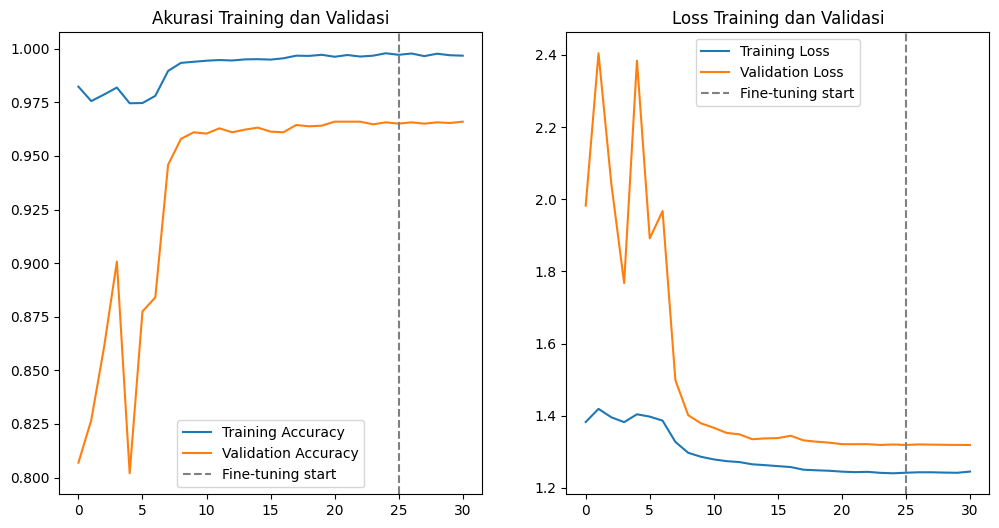

In [13]:
acc = history1.history['accuracy'] + history_fine.history['accuracy']
val_acc = history1.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history1.history['loss'] + history_fine.history['loss']
val_loss = history1.history['val_loss'] + history_fine.history['val_loss']

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.axvline(x=len(history1.history['accuracy'])-1, color='gray', linestyle='--', label='Fine-tuning start')
plt.legend()
plt.title('Akurasi Training dan Validasi')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.axvline(x=len(history1.history['loss'])-1, color='gray', linestyle='--', label='Fine-tuning start')
plt.legend()
plt.title('Loss Training dan Validasi')
plt.show()

## 13. Evaluasi pada Test Set

Menggunakan model terbaik yang disimpan oleh ModelCheckpoint.

In [14]:
best_model = tf.keras.models.load_model('submission/best_model.keras')

test_loss, test_accuracy = best_model.evaluate(test_generator, verbose=1)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

if test_accuracy >= 0.95:
    print("✅ Model memenuhi target akurasi >=95%.")
else:
    print("⚠️  Model belum mencapai 95%.")

106/106 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9646 - loss: 1.3435

Test Loss: 1.3435
Test Accuracy: 0.9646
✅ Model memenuhi target akurasi >=95%.


## 14. Confusion Matrix dan Classification Report

Menampilkan matriks kebingungan dan laporan klasifikasi per kelas.

2026-02-16 19:12:17.868852: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
/home/asephs/venvs/ml311/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/asephs/venvs/ml311/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/asephs/venvs/ml311/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples.


Classification Report:
              precision    recall  f1-score   support

        Abra       0.83      0.83      0.83        12
  Aerodactyl       0.94      1.00      0.97        17
    Alakazam       0.79      0.88      0.83        17
       Arbok       1.00      0.96      0.98        27
    Arcanine       0.89      0.94      0.91        17
    Articuno       1.00      1.00      1.00        20
    Beedrill       1.00      1.00      1.00        18
  Bellsprout       0.93      1.00      0.96        26
   Blastoise       1.00      1.00      1.00        30
   Bulbasaur       1.00      1.00      1.00        31
  Butterfree       1.00      0.96      0.98        25
    Caterpie       1.00      1.00      1.00        26
     Chansey       1.00      1.00      1.00        23
   Charizard       1.00      0.95      0.98        22
  Charmander       1.00      1.00      1.00        26
  Charmeleon       1.00      1.00      1.00        29
    Clefable       1.00      1.00      1.00        21
   

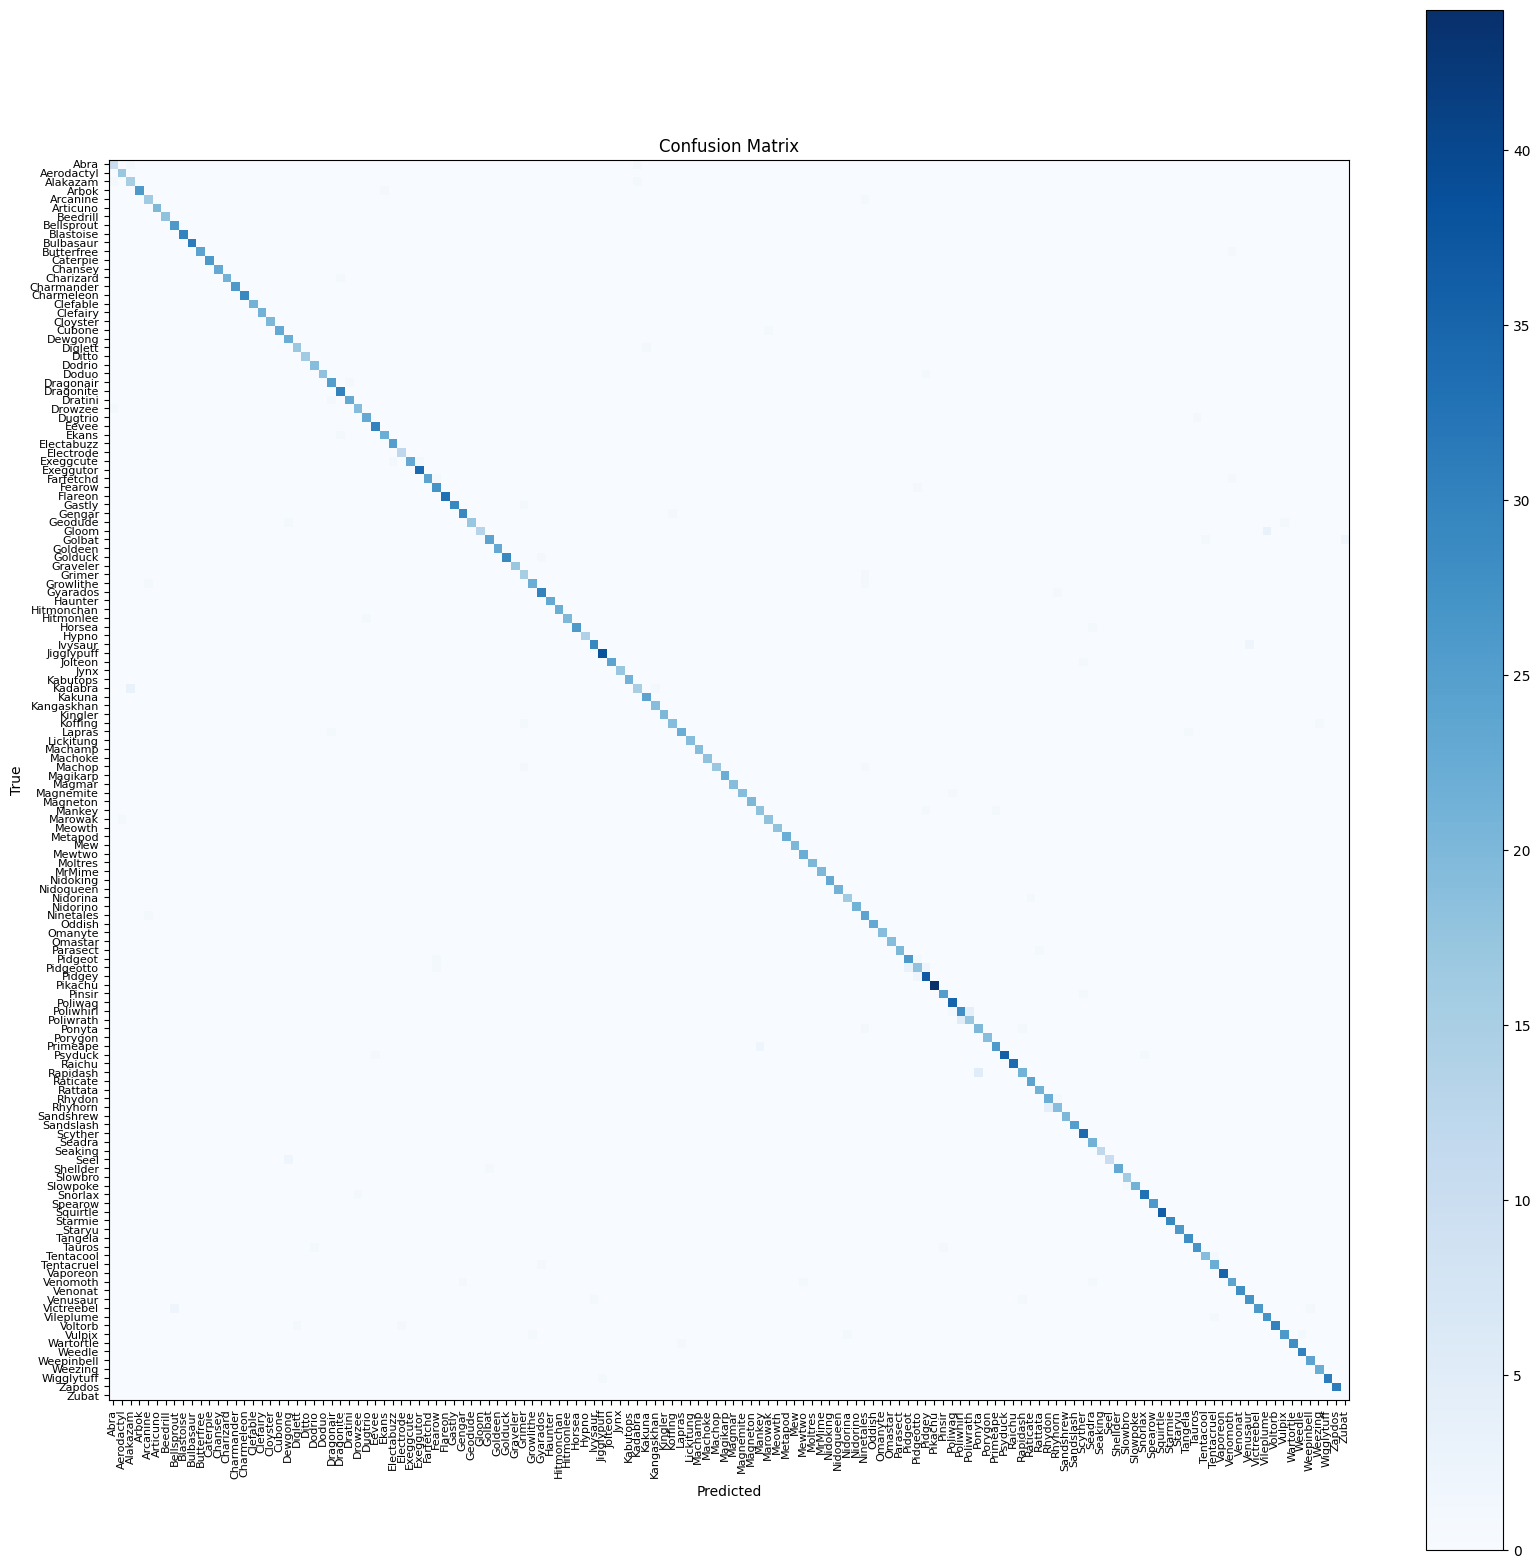

In [15]:
# Kumpulkan label sebenarnya dan prediksi
y_true = []
y_pred_probs = []
for images, labels in test_generator:
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    preds = best_model.predict(images, verbose=0)
    y_pred_probs.extend(preds)

y_true = np.array(y_true)
y_pred = np.argmax(np.array(y_pred_probs), axis=1)

# Laporan klasifikasi
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(20, 20))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names, rotation=90, fontsize=8)
plt.yticks(tick_marks, class_names, fontsize=8)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

## 15. Simpan Model dalam Berbagai Format

Menyimpan model dalam format SavedModel, TF-Lite, H5 (keras), dan TFJS.

In [20]:
%run export_model.py

2026-02-16 19:15:38,035 [INFO] === EXPORT STARTED ===
2026-02-16 19:15:38,036 [INFO] Loading model...
2026-02-16 19:15:38,642 [INFO] Model loaded successfully
2026-02-16 19:15:38,643 [INFO] Exporting SavedModel...


INFO:tensorflow:Assets written to: /home/asephs/Pijak/Proyek_Klasifikasi_Gambar/submission/saved_model/assets


2026-02-16 19:15:41,873 [INFO] Assets written to: /home/asephs/Pijak/Proyek_Klasifikasi_Gambar/submission/saved_model/assets
2026-02-16 19:15:41,899 [INFO] SavedModel OK
2026-02-16 19:15:41,899 [INFO] Converting to TFLite...


INFO:tensorflow:Assets written to: /tmp/tmpvjztlxwn/assets


2026-02-16 19:15:44,461 [INFO] Assets written to: /tmp/tmpvjztlxwn/assets


Saved artifact at '/tmp/tmpvjztlxwn'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float16, name='input_layer_2')
Output Type:
  TensorSpec(shape=(None, 142), dtype=tf.float32, name=None)
Captures:
  140331207465616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140331207463312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140331207465808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140331207464080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140331207464272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140331207464848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140331207466000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140331207466960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140331207465232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140331207467152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  14033120746

W0000 00:00:1771244145.258214  333348 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1771244145.258228  333348 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
2026-02-16 19:15:45.258514: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /tmp/tmpvjztlxwn
2026-02-16 19:15:45.264209: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-02-16 19:15:45.264226: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpvjztlxwn
I0000 00:00:1771244145.333435  333348 mlir_graph_optimization_pass.cc:425] MLIR V1 optimization pass is not enabled
2026-02-16 19:15:45.344875: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2026-02-16 19:15:45.781412: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpvjztlxwn
2026-02-16 19:15:45.888139: I tensorflow/cc/saved_model/loader.cc:471] SavedModel 

## 16. Inference dengan Model TF-Lite

Menguji model TF-Lite pada sampel acak dari test set.

Found 3411 files belonging to 142 classes.


I0000 00:00:1771244182.632821  333348 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2931 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


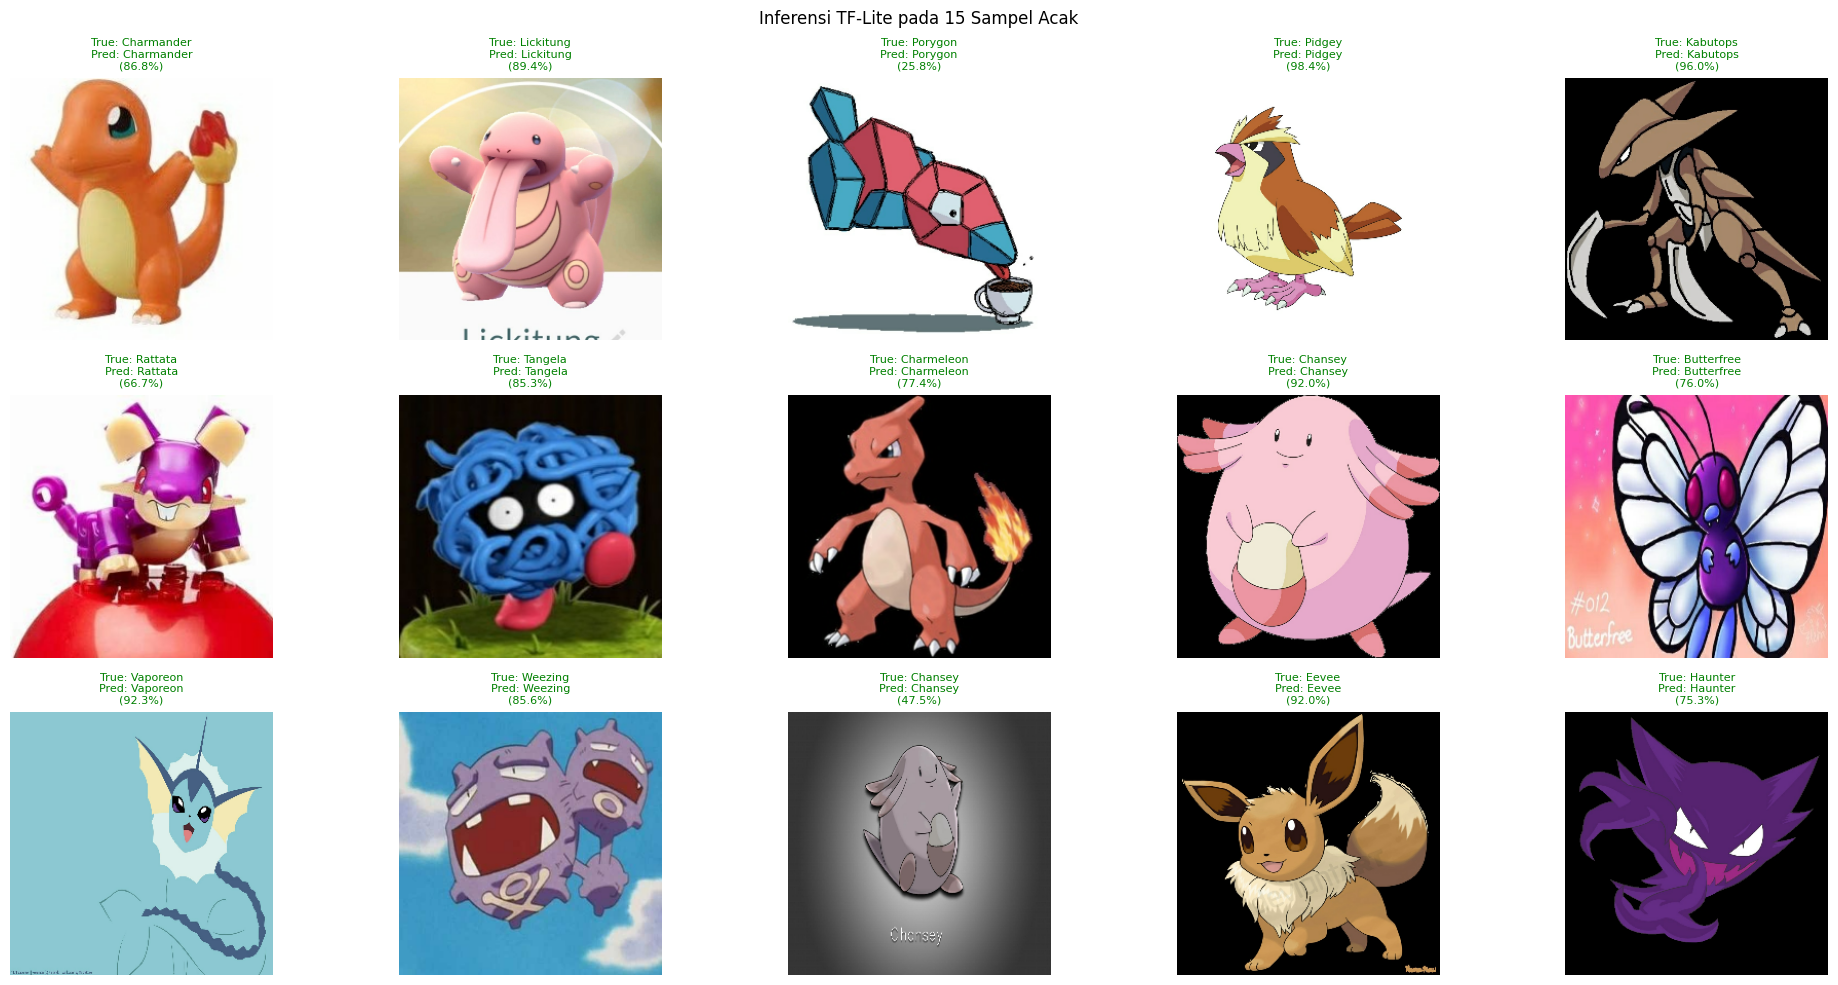

In [23]:
# Load interpreter
interpreter = tf.lite.Interpreter(model_path='submission/tflite/model.tflite')
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

input_index = input_details[0]['index']
input_dtype = input_details[0]['dtype']
input_scale, input_zero_point = input_details[0]['quantization']

output_index = output_details[0]['index']
output_scale, output_zero_point = output_details[0]['quantization']

# Ambil batch acak dari test set
viz_ds = image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=32,
    label_mode='categorical',
    shuffle=True,
    seed=random.randint(0, 1000)
)

images, labels = next(iter(viz_ds.map(preprocess)))

plt.figure(figsize=(20, 10))

for i in range(15):
    img = images[i].numpy()
    true_idx = np.argmax(labels[i])
    true_name = class_names[true_idx]

    # Persiapan input
    input_data = np.expand_dims(img, axis=0)

    if input_dtype == np.uint8 or input_dtype == np.int8:
        # Quantized model
        input_data = input_data / input_scale + input_zero_point
        input_data = np.round(input_data).astype(input_dtype)
    else:
        # Float model
        input_data = input_data.astype(input_dtype)

    interpreter.set_tensor(input_index, input_data)
    interpreter.invoke()

    output = interpreter.get_tensor(output_index)

    # Dequantize jika perlu
    if output_scale > 0:
        output = (output.astype(np.float32) - output_zero_point) * output_scale

    pred_idx = np.argmax(output[0])
    pred_name = class_names[pred_idx]
    conf = float(output[0][pred_idx]) * 100

    display_img = img.astype("uint8")

    plt.subplot(3, 5, i + 1)
    plt.imshow(display_img)
    color = 'green' if pred_idx == true_idx else 'red'
    plt.title(f"True: {true_name}\nPred: {pred_name}\n({conf:.1f}%)",
              fontsize=8, color=color)
    plt.axis('off')

plt.suptitle("Inferensi TF-Lite pada 15 Sampel Acak")
plt.tight_layout()
plt.show()

## 17. Inference Interaktif (Upload Gambar) dengan Grad-CAM

Widget untuk mengunggah gambar sendiri dan melihat prediksi beserta Grad-CAM.
Layer konvolusi terakhir dicari secara otomatis dari base model.

In [ ]:
# Fungsi Grad-CAM yang robust
def find_last_conv_layer(model):
    """Cari layer konvolusi terakhir dalam base model."""
    base_model = model.layers[0]
    for layer in reversed(base_model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer.name
    raise ValueError("Tidak ditemukan layer Conv2D dalam base model.")

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    base_model = model.layers[0]
    
    # Model yang mengeluarkan output dari conv layer dan base model
    grad_model = tf.keras.models.Model(
        inputs=[base_model.inputs],
        outputs=[base_model.get_layer(last_conv_layer_name).output, base_model.output]
    )
    
    with tf.GradientTape() as tape:
        conv_output, base_output = grad_model(img_array)
        # Forward melalui classifier head
        x = base_output
        for layer in model.layers[1:]:
            x = layer(x, training=False)
        preds = x
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_output = conv_output[0]
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

def save_and_display_gradcam(img, heatmap, alpha=0.4):
    img = tf.keras.preprocessing.image.img_to_array(img)
    heatmap = np.uint8(255 * heatmap)
    jet = plt.colormaps.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]
    jet_heatmap = tf.keras.preprocessing.image.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.shape[1], img.shape[0]))
    jet_heatmap = tf.keras.preprocessing.image.img_to_array(jet_heatmap)
    superimposed_img = jet_heatmap * alpha + img
    return tf.keras.preprocessing.image.array_to_img(superimposed_img)

# Widget upload
upload_btn = widgets.FileUpload(accept='image/*', multiple=False, description='Upload', icon='upload')
out = widgets.Output()

last_conv_name = find_last_conv_layer(best_model)
print(f"Layer konvolusi terakhir: {last_conv_name}")

def on_upload(change):
    # Handle berbagai versi ipywidgets
    if isinstance(upload_btn.value, tuple):
        uploaded_file = upload_btn.value[0]
    else:
        uploaded_file = next(iter(upload_btn.value.values()))
    content = uploaded_file['content']
    try:
        image = Image.open(io.BytesIO(content)).convert('RGB')
        with out:
            clear_output(wait=True)
            plt.figure(figsize=(10, 5))
            plt.subplot(1, 2, 1)
            plt.imshow(image)
            plt.title("Gambar Asli")
            plt.axis('off')

            # Preprocessing
            img_resized = image.resize(IMG_SIZE)
            img_array = tf.keras.preprocessing.image.img_to_array(img_resized)
            img_array = tf.expand_dims(img_array, 0)
            img_array = preprocess_input(img_array)

            # Prediksi
            preds = best_model.predict(img_array, verbose=0)
            pred_idx = np.argmax(preds[0])
            pred_label = class_names[pred_idx]
            confidence = preds[0][pred_idx]

            # Grad-CAM
            heatmap = make_gradcam_heatmap(img_array, best_model, last_conv_name, pred_idx)
            result = save_and_display_gradcam(img_resized, heatmap)

            plt.subplot(1, 2, 2)
            plt.imshow(result)
            plt.title(f"Pred: {pred_label} ({confidence:.2%})")
            plt.axis('off')
            plt.show()
    except Exception as e:
        with out:
            clear_output()
            print(f"Error: {e}")
            traceback.print_exc()

upload_btn.observe(on_upload, names='value')
display(widgets.VBox([widgets.Label("Upload Gambar Pokemon:"), upload_btn, out]))


Layer konvolusi terakhir: conv_1


## 18. Model Card (Dokumentasi)

Informasi lengkap tentang model yang telah dilatih.

- **Nama Model**: Pokemon-Gen1-MobileNetV3-Large (v2.1 - Peningkatan Regularisasi)
- **Versi**: 2.1
- **Arsitektur**: MobileNetV3Large (Transfer Learning) dengan dropout internal 0.3 + classifier Dense 1024 (L2 reg) + Dropout 0.6
- **Framework**: TensorFlow 2.x / Keras
- **Dataset**: ~17.000 gambar Pokemon Generasi 1 (140+ kelas)
- **Target Akurasi**: ≥95% pada validasi dan test
- **Input**: Gambar RGB 256x256
- **Output**: Probabilitas untuk setiap kelas Pokemon
- **Cara Pakai**: Gunakan model untuk klasifikasi gambar Pokemon Generasi 1.
- **Etika**: Model ini hanya untuk tujuan edukasi. Hak cipta Pokemon milik Nintendo/Game Freak.

### Ringkasan Perubahan untuk Mencapai >95%
1. **Regularisasi lebih kuat**:
   - L2 regularization (1e-4) pada Dense layer.
   - Dropout ditingkatkan menjadi 0.6.
   - Dropout internal MobileNet diaktifkan (0.3).
2. **Augmentasi ditambah GaussianNoise** untuk variasi data.
3. **Label smoothing ditingkatkan menjadi 0.15**.
4. **Pembatasan class weight lebih ketat** (max 3.0).
5. **Fine-tuning dengan learning rate lebih kecil** (5e-6).
6. **Early stopping patience dinaikkan** menjadi 20.
7. **Optimizer AdamW tetap digunakan** dengan weight decay.
8. **Evaluasi dan monitoring** dengan TensorBoard dan CSVLogger.